# Sentinel-5P NO₂ over Delhi — Download, Analyse, Visualise

**GeoAI Professional Program · Practical Session**

In Google Earth Engine we exported Sentinel-5P (TROPOMI) NO₂ data to Google Drive.
In this notebook we bring that data into Python and do the analysis ourselves.

| Step | What we do |
|---|---|
| 1 | Set up libraries and data paths |
| 2 | Open the GeoTIFFs and inspect metadata |
| 3 | Convert units and clean no-data values |
| 4 | Map monsoon vs winter NO₂ with the Delhi boundary |
| 5 | Calculate statistics inside Delhi |
| 6 | Difference map and percentage change |
| 7 | Compare value distributions (histogram) |
| 8 | Monthly time series 2019–2026 and seasonal cycle |
| 9 | Compare Indian cities |
| 10 | Summary and assignment |

**Input files** (from the Drive folder `S5P_Delhi`, placed in a `data/` folder next to this notebook):
`Delhi_NO2_Jul2025.tif`, `Delhi_NO2_Nov2025.tif`, `Delhi_NO2_monthly.csv`, `City_NO2_2025.csv`, `Delhi_boundary.geojson`

## 1. Setup

In [1]:
# Run once if a library is missing:
# !pip install rasterio geopandas matplotlib pandas numpy

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("Data")          # folder holding the 5 exported files
plt.rcParams["figure.dpi"] = 110

for f in sorted(DATA.glob("*")):
    print(f.name)

City_NO2_2025.csv
Delhi_boundary.geojson
Delhi_NO2_Jul2025.tif
Delhi_NO2_monthly.csv
Delhi_NO2_Nov2025.tif


## 2. Open the rasters and inspect metadata

Before any analysis, always check **what** the file contains: coordinate system, size, pixel size and no-data value.

In [2]:
jul_path = DATA / "Delhi_NO2_Jul2025.tif"
nov_path = DATA / "Delhi_NO2_Nov2025.tif"

with rasterio.open(jul_path) as src:
    print("CRS        :", src.crs)
    print("Size       :", src.width, "x", src.height, "pixels")
    print("Bands      :", src.count)
    print("Pixel size :", src.res, "(degrees)")
    print("Bounds     :", src.bounds)
    print("No-data    :", src.nodata)
    print("Data type  :", src.dtypes[0])

CRS        : EPSG:4326
Size       : 101 x 81 pixels
Bands      : 1
Pixel size : (0.010000045742818514, 0.010000045742818514) (degrees)
Bounds     : BoundingBox(left=76.590350344247, bottom=28.19012894900539, right=77.60035496427167, top=29.00013265417369)
No-data    : None
Data type  : float32


**Discuss:** the pixel size is ~0.01° (about 1.1 km grid), but the real TROPOMI footprint is ~5.5 × 3.5 km.
The grid is finer than the sensor — neighbouring pixels are not fully independent.

## 3. Read, clean and convert units

* GEE exported masked pixels as **-9999** → we turn them into `NaN`.
* Values are in **mol/m²** (very small numbers like 0.00012). We multiply by 10⁶ to get **µmol/m²**, which is easier to read.

In [3]:
NODATA = -9999
TO_UMOL = 1e6   # mol/m² -> µmol/m²

def read_no2(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        extent = plotting_extent(src)
    arr[arr == NODATA] = np.nan
    return arr * TO_UMOL, extent

jul, extent = read_no2(jul_path)
nov, _ = read_no2(nov_path)

print("July  : min %.1f  max %.1f µmol/m²" % (np.nanmin(jul), np.nanmax(jul)))
print("Nov   : min %.1f  max %.1f µmol/m²" % (np.nanmin(nov), np.nanmax(nov)))
print("No-data pixels — July:", np.isnan(jul).sum(), " Nov:", np.isnan(nov).sum())

July  : min 27.4  max 88.5 µmol/m²
Nov   : min 46.0  max 171.0 µmol/m²
No-data pixels — July: 0  Nov: 0


**Note:** small negative values can appear. They are retrieval noise over clean areas, not "negative pollution".
We keep them for averaging (removing them would bias the mean upward).

## 4. Map monsoon vs winter NO₂

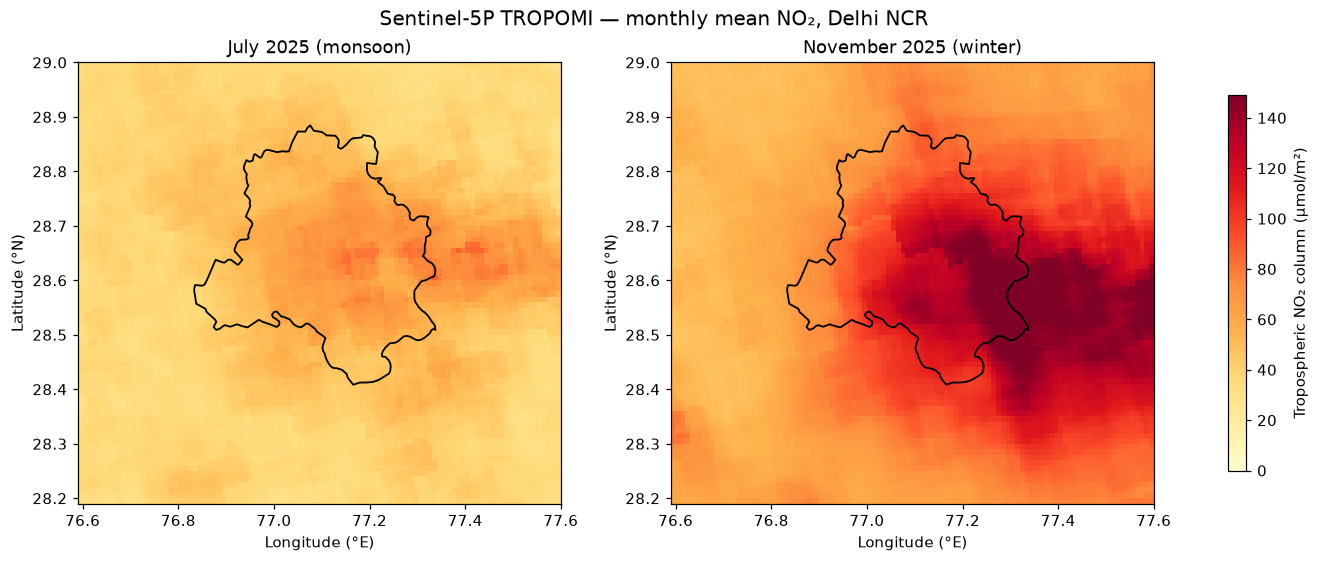

In [4]:
delhi = gpd.read_file(DATA / "Delhi_boundary.geojson").to_crs("EPSG:4326")

# Same colour scale for both maps — otherwise the comparison is misleading
vmin = 0
vmax = np.nanpercentile(np.concatenate([jul.ravel(), nov.ravel()]), 98)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, arr, title in zip(axes, [jul, nov],
                          ["July 2025 (monsoon)", "November 2025 (winter)"]):
    im = ax.imshow(arr, extent=extent, cmap="YlOrRd", vmin=vmin, vmax=vmax)
    delhi.boundary.plot(ax=ax, color="black", linewidth=1.2)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

fig.colorbar(im, ax=axes, shrink=0.85,
             label="Tropospheric NO₂ column (µmol/m²)")
fig.suptitle("Sentinel-5P TROPOMI — monthly mean NO₂, Delhi NCR", fontsize=13)
plt.show()

**Interpret:**
1. Where are the highest values? Inside Delhi, or spread across NCR?
2. How different do the two months look?
3. Why must both maps use the **same** colour scale?

## 5. Statistics inside the Delhi boundary

We clip (mask) each raster with the Delhi polygon, then compute summary statistics.
Compare these numbers with the ones printed in the GEE Console — they should be very close.

In [5]:
def clip_to_delhi(path):
    with rasterio.open(path) as src:
        out, _ = mask(src, delhi.geometry, crop=True, nodata=NODATA, filled=True)
    arr = out[0].astype("float64")
    arr[arr == NODATA] = np.nan
    return arr * TO_UMOL

jul_d = clip_to_delhi(jul_path)
nov_d = clip_to_delhi(nov_path)

def summary(arr):
    v = arr[~np.isnan(arr)]
    return {"pixels": v.size, "mean": v.mean(), "median": np.median(v),
            "min": v.min(), "max": v.max(), "std": v.std()}

stats = pd.DataFrame({"July 2025": summary(jul_d),
                      "Nov 2025": summary(nov_d)}).T.round(1)
stats

,pixels,mean,median,min,max,std
July 2025,1387.0,59.7,60.1,35.8,84.2,9.9
Nov 2025,1387.0,110.9,111.4,63.6,170.3,26.6


In [6]:
pct = (stats.loc["Nov 2025", "mean"] - stats.loc["July 2025", "mean"]) \
      / stats.loc["July 2025", "mean"] * 100
ratio = stats.loc["Nov 2025", "mean"] / stats.loc["July 2025", "mean"]
print(f"Mean NO₂ over Delhi changed by {pct:+.1f}% from July to November")
print(f"November is {ratio:.1f}× the July level")

Mean NO₂ over Delhi changed by +85.8% from July to November
November is 1.9× the July level


## 6. Difference map — where did NO₂ increase most?

`Difference = November − July`. A **diverging** colour map (blue–white–red) centred on zero shows increase and decrease.

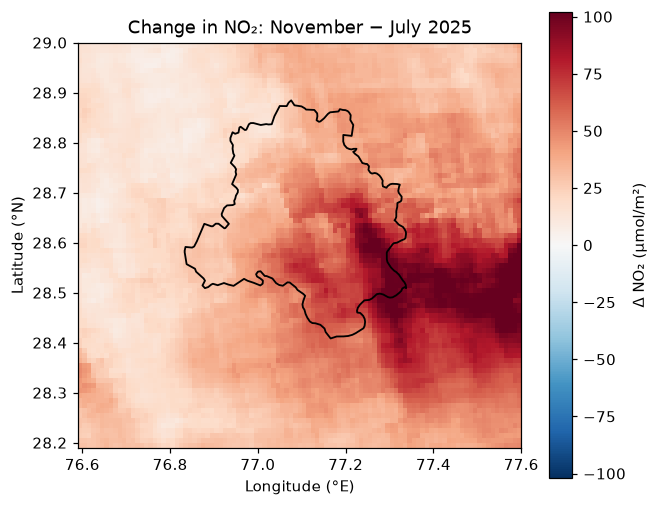

In [7]:
diff = nov - jul
lim = np.nanpercentile(np.abs(diff), 98)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(diff, extent=extent, cmap="RdBu_r", vmin=-lim, vmax=lim)
delhi.boundary.plot(ax=ax, color="black", linewidth=1.2)
ax.set_title("Change in NO₂: November − July 2025")
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
fig.colorbar(im, ax=ax, label="Δ NO₂ (µmol/m²)")
plt.show()

## 7. Distribution of pixel values

A histogram shows the whole spread of values, not just the average.

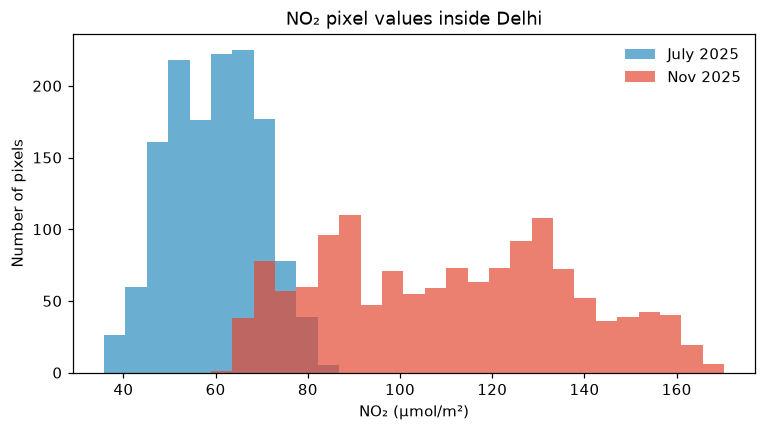

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(np.nanmin([jul_d, nov_d]), np.nanmax([jul_d, nov_d]), 30)
ax.hist(jul_d[~np.isnan(jul_d)], bins=bins, alpha=0.7, label="July 2025", color="#2b8cbe")
ax.hist(nov_d[~np.isnan(nov_d)], bins=bins, alpha=0.7, label="Nov 2025", color="#e34a33")
ax.set_xlabel("NO₂ (µmol/m²)"); ax.set_ylabel("Number of pixels")
ax.set_title("NO₂ pixel values inside Delhi")
ax.legend(frameon=False)
plt.show()

## 8. Monthly time series, 2019–2026

This CSV was computed in GEE: one row per month, mean NO₂ over Delhi.

In [9]:
ts = pd.read_csv(DATA / "Delhi_NO2_monthly.csv", parse_dates=["date"])
ts["no2"] = ts["no2_mol_m2"] * TO_UMOL
ts = ts.sort_values("date").reset_index(drop=True)

print("Months:", len(ts), " | Missing values:", ts["no2"].isna().sum())
ts.head()

Months: 93  | Missing values: 0


,date,no2_mol_m2,n_images,no2
0,2019-01-01,0.000172,440,172.035963
1,2019-02-01,0.000146,396,145.631542
2,2019-03-01,0.000083,440,82.953292
3,2019-04-01,0.000101,417,100.832351
4,2019-05-01,0.000094,440,93.521064


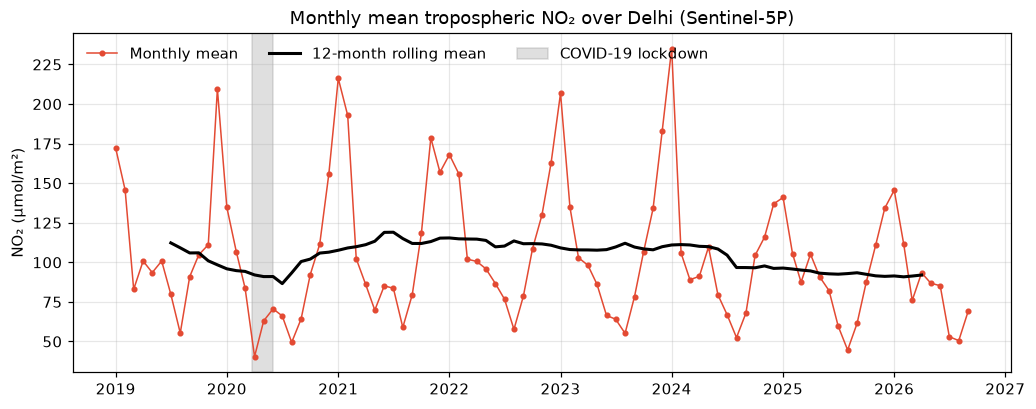

In [10]:
ts["rolling_12"] = ts["no2"].rolling(12, center=True, min_periods=12).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ts["date"], ts["no2"], marker="o", markersize=3, linewidth=1,
        color="#e34a33", label="Monthly mean")
ax.plot(ts["date"], ts["rolling_12"], color="black", linewidth=2,
        label="12-month rolling mean")

# Highlight the COVID-19 lockdown
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"),
           color="grey", alpha=0.25, label="COVID-19 lockdown")

ax.set_ylabel("NO₂ (µmol/m²)")
ax.set_title("Monthly mean tropospheric NO₂ over Delhi (Sentinel-5P)")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(alpha=0.3)
plt.show()

**Interpret:** Do you see a repeating yearly pattern? What happened during spring 2020?
Is there any long-term trend in the rolling mean?

### 8b. Seasonal cycle — the average year

We group all years by calendar month to get the typical seasonal pattern, then by season.

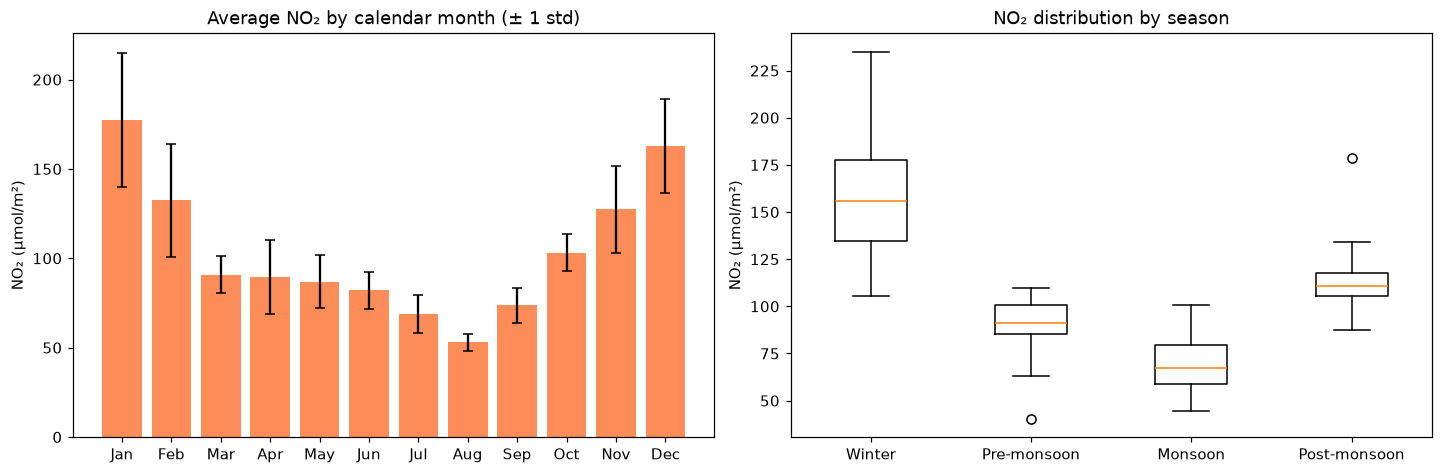

season
Winter (DJF)         157.3
Pre-monsoon (MAM)     89.1
Monsoon (JJAS)        69.4
Post-monsoon (ON)    115.3
Name: no2, dtype: float64

In [11]:
ts["month"] = ts["date"].dt.month

def season(m):
    if m in (12, 1, 2):  return "Winter (DJF)"
    if m in (3, 4, 5):   return "Pre-monsoon (MAM)"
    if m in (6, 7, 8, 9): return "Monsoon (JJAS)"
    return "Post-monsoon (ON)"

ts["season"] = ts["month"].apply(season)

clim = ts.groupby("month")["no2"].agg(["mean", "std"])
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)

axes[0].bar(names, clim["mean"], yerr=clim["std"], capsize=3, color="#fc8d59")
axes[0].set_ylabel("NO₂ (µmol/m²)")
axes[0].set_title("Average NO₂ by calendar month (± 1 std)")

order = ["Winter (DJF)", "Pre-monsoon (MAM)", "Monsoon (JJAS)", "Post-monsoon (ON)"]
data = [ts.loc[ts["season"] == s, "no2"].dropna() for s in order]
axes[1].boxplot(data)
axes[1].set_xticks(range(1, 5), [o.split(" ")[0] for o in order])
axes[1].set_title("NO₂ distribution by season")
axes[1].set_ylabel("NO₂ (µmol/m²)")
plt.show()

ts.groupby("season")["no2"].mean().reindex(order).round(1)

**Discuss — why is winter worse?**
temperature inversion traps pollutants near the ground · low wind speed · crop-residue burning in Punjab/Haryana ·
festival season · heating. **Why is the monsoon cleaner?** rain washout, stronger winds, and more cloud
(which also means fewer valid satellite observations — check the `n_images` column).

## 9. City comparison — 2025 annual mean

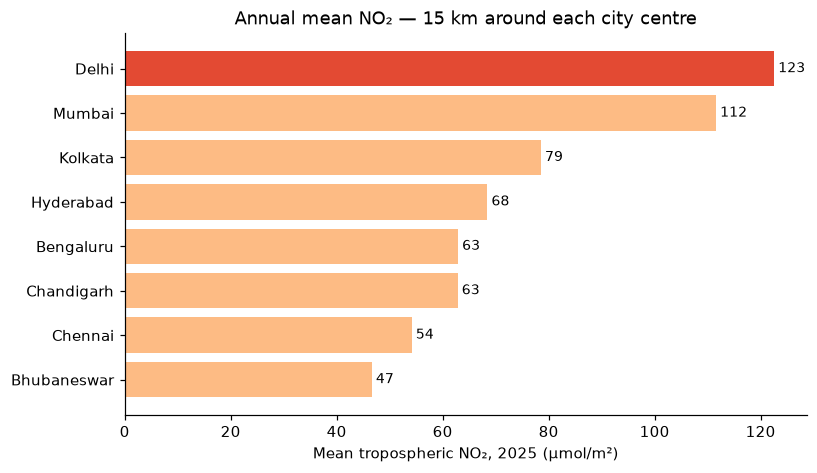

,city,no2
0,Delhi,122.6
1,Mumbai,111.6
2,Kolkata,78.6
3,Hyderabad,68.4
4,Bengaluru,62.9
5,Chandigarh,62.8
6,Chennai,54.2
7,Bhubaneswar,46.6


In [12]:
cities = pd.read_csv(DATA / "City_NO2_2025.csv")
cities["no2"] = cities["mean"] * TO_UMOL
cities = cities.sort_values("no2")

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#e34a33" if c == "Delhi" else "#fdbb84" for c in cities["city"]]
ax.barh(cities["city"], cities["no2"], color=colors)
for y, v in enumerate(cities["no2"]):
    ax.text(v, y, f" {v:.0f}", va="center", fontsize=9)
ax.set_xlabel("Mean tropospheric NO₂, 2025 (µmol/m²)")
ax.set_title("Annual mean NO₂ — 15 km around each city centre")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

cities[["city", "no2"]].sort_values("no2", ascending=False).round(1).reset_index(drop=True)

## 10. Summary

| Concept | What we learned |
|---|---|
| Units | S5P gives a **column density** (mol/m²) — the total gas above a point, not the ground AQI value (µg/m³) |
| Composites | Monthly means remove gaps and noise from single-day images |
| Same colour scale | Essential for fair visual comparison |
| Statistics | Mean, median, min, max, std inside a boundary using `rasterio.mask` |
| Change | Difference maps and % change reveal seasonal effects |
| Time series | Clear winter peaks and monsoon lows; lockdown dip in 2020 |
| Limitations | ~5.5 km pixels, cloud gaps, wind transport, retrieval noise |

### Assignment — two-period pollution comparison
1. In GEE, change the study area to **your own city** (not Delhi) and export a monsoon and a winter month.
2. Re-run this notebook on your files.
3. Report mean, min and max for both periods and the % change.
4. Write **three observations** explaining the difference.
5. Push the GEE script, notebook and figures to your **GitHub** repository.

**Bonus:** compare April 2019 with April 2020 (COVID-19 lockdown) for your city.